# Nondeterministic Actions: Solving Tic-Tac-Toe with AND-OR-Tree Search

## Introduction 
 
Multiplayer games can be implemented as:
1. __Nondeterministic actions:__ The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. Monte Carlo Tree search: Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)).

We will implement
* __AND-OR-Tree search.__

Each action consists of the move by the player (OR levels in the tree) and all possible (i.e., nondeterministic) responses by the opponents (AND levels). The action therefore results in a set of possible states.

We will search for a __conditional plan__ using AND-OR-Tree search. 

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [36]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [37]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

## Solving Tic-Tac-Toe using AND-OR-Tree Search

The opponent can be modeled as part of the environment. The opponent's action as a response to the agent's 
action makes the environment appear non-deterministic (see AIMA page 125 or the slides). The ADS-OR-Tree algorithm uses the following functions:

* `is_goal(state)`: determine if the current board/state has a winner.
* `is_cycle(path)`: determine if we are in a loop (the tic-tac-toe problem has no loops so I do not implement it).
* `results(state, action)`: returns all states following state + action.


### Cycles

The path is typically used for loop checking. We ignore it here since tic-tac-toe does not have cycles.

### Goals

Reaching the goal means that the agent has successfully finished the task. 

For games, `terminal(s)` checks if `s` is a terminal state, but a terminal state can also indicate that 
the player lost (which indicates a failure). This can determined by the 
`utility(s)` function. Tic-tac-toe also has draws and we need to decide if a draw is considered successfully reaching
the goal or a failure.

### Non-deterministic Results

Since the opponent and her moves are part of the environment, `results()` returns for a state $\times$ action combination a set of new states that reflects all possible responses by the opponent.

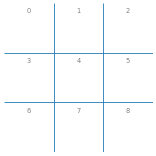


Set of possible state for placing an x at position 4 of an empty board and the opponent's move:


[['o', ' ', ' ', ' ', 'x', ' ', ' ', ' ', ' '],
 [' ', 'o', ' ', ' ', 'x', ' ', ' ', ' ', ' '],
 [' ', ' ', 'o', ' ', 'x', ' ', ' ', ' ', ' '],
 [' ', ' ', ' ', 'o', 'x', ' ', ' ', ' ', ' '],
 [' ', ' ', ' ', ' ', 'x', 'o', ' ', ' ', ' '],
 [' ', ' ', ' ', ' ', 'x', ' ', 'o', ' ', ' '],
 [' ', ' ', ' ', ' ', 'x', ' ', ' ', 'o', ' '],
 [' ', ' ', ' ', ' ', 'x', ' ', ' ', ' ', 'o']]

In [38]:
def results(state, action, player = 'x'):
    """produce the set of states after the provided action for player. 
       It is the set of boards with the action and all possible reactions by the opponent."""
    
    opponent = other(player)
    state = state.copy()
    
    # player's move
    state[action] = player
    
    # opponent reacts
    r = list()
    o_actions = actions(state)
    
    # board is full
    if len(o_actions) < 1 : return [state]
    
    for o_a in o_actions:
        s = state.copy()
        s[o_a] = opponent
        r.append(s)    
    
    return r

show_board(empty_board())

print()
print("Set of possible state for placing an x at position 4 of an empty board and the opponent's move:")
results(empty_board(), 4)

=== TEST results() ===
X plays at position 4
Number of possible states: 8
State 1: X at 4, O at 0
State 2: X at 4, O at 1
State 3: X at 4, O at 2
State 4: X at 4, O at 3
State 5: X at 4, O at 5
State 6: X at 4, O at 6
State 7: X at 4, O at 7
State 8: X at 4, O at 8

Example state:


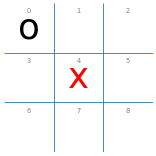

In [39]:
# TEST 1: Nước đi của X và các phản ứng của O

board = empty_board()

possible_states = results(board, 4, player='x')

print("=== TEST results() ===")
print("X plays at position 4")
print("Number of possible states:", len(possible_states))

for i, state in enumerate(possible_states):
    print(f"State {i + 1}: X at 4, O at {state.index('o')}")

print("\nExample state:")
show_board(possible_states[0])

### Recursive AND-OR Search (DFS)

In [40]:
# define global variables for debugging
DEBUG = 1
COUNT = 0 # used to report the number of searched nodes

def and_or_search(state, player = 'x', draw_is_win = True):
    """start the search. Consider draw_is_win a goal state?"""
    global DEBUG, COUNT
    COUNT = 0
    
    plan = or_search(state, player, draw_is_win)
    
    if DEBUG >= 1: 
        print(f"Number of nodes searched: {COUNT}")  
    
    return plan
 

def or_search(state, player, draw_is_win):
    """Or step of the search: the player makes a move. 
    We try all possible action and return a conditional 
    plan for the first action that only has goal states as leaf nodes. 
    If none can be found, then failure (None) is returned.
    
    Note: path is not used in this implementation since tic-tac-toe does not 
    need cycle checking.
    """
    global DEBUG, COUNT
    COUNT += 1
    
    # goal check
    u = utility(state, player)
    if u == -1 or (not draw_is_win and u == 0): return None # failure
     
    # cycles check: tic-tac-toe has no cycles

    # check all possible actions
    for action in actions(state):
        plan = and_search(results(state, action, player), player, draw_is_win)
        if plan is not None: 
            return [action, plan]
    
    # failure
    return None


def and_search(states, player, draw_is_win):
    """And step of the search: Represents all opponent's possible moves. 
    Follow all possible states (call the or step). 
    Return a conditional plan only if all paths lead to a goal state."""
    global DEBUG, COUNT
    COUNT += 1
    
    # return plans only if no state fails
    plans = []
    for s in states:
        # goal check
        u = utility(s, player)
        if u == 1: return "win"  # success
        if draw_is_win and u == 0: return "draw"

        plan = or_search(s, player, draw_is_win)
        
        if plan is None: 
            return None    # found a state that fails so we abandon this subtree!
        plans.append(['if', s, 'then', plan])
        
    return plans

And-or search looks for a subtree (i.e., an action) that guarantees a win and returns a conditional plan for this subtree. If no such subtree exists, no plan is returned. The algorithm only searches a fraction of the game tree since it abandons the current subtree when it finds the first leaf node that is not a win (see `and_search` function).

# Some Tests

## x is about to win

Board:


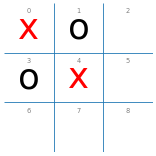


Win or draw:
Number of nodes searched: 22


[2,
 [['if', ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '], 'then', [6, 'win']],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', 'o', ' ', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', 'o', ' ', 'o'],
      'then',
      [7, 'draw']]]]],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', ' ', 'o', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
      'then',
      [6, 'win']]]]],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', ' ', ' ', 'o'],
   'then',
   [5,
    [['if',
      ['x', 'o', 'x', 'o', 'x', 'x', 'o', ' ', 'o'],
      'then',
      [7, 'draw']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
      'then',
      [6, 'win']]]]]]]

CPU times: total: 0 ns
Wall time: 3.83 ms


In [41]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

Why does it play 2 and not 8!!!

In [42]:
print("Win only:")
%time display(and_or_search(board, player = 'x', draw_is_win = False))

Win only:
Number of nodes searched: 30


[2,
 [['if', ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '], 'then', [6, 'win']],
  ['if', ['x', 'o', 'x', 'o', 'x', ' ', 'o', ' ', ' '], 'then', [8, 'win']],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', ' ', 'o', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
      'then',
      [6, 'win']]]]],
  ['if', ['x', 'o', 'x', 'o', 'x', ' ', ' ', ' ', 'o'], 'then', [6, 'win']]]]

CPU times: total: 0 ns
Wall time: 4.1 ms


### Nhận xét kiểm thử 1 – X sắp thắng

Thực nghiệm được thực hiện trên trạng thái bàn cờ có X tại các vị trí 0 và 4, O tại các vị trí 1 và 3. Trong trạng thái này, X có thể thắng ngay bằng cách đánh vào vị trí 8 để hoàn thành đường chéo 0–4–8.

Khi chạy AND-OR Search với `draw_is_win=True`, thuật toán lựa chọn nước đi 2 và duyệt 22 nút. Kế hoạch trả về cho phép X đạt kết quả thắng hoặc hòa tùy theo phản ứng của đối thủ.

Khi thay đổi thành `draw_is_win=False`, thuật toán vẫn lựa chọn nước đi 2 nhưng số nút tìm kiếm tăng lên 30. Kế hoạch điều kiện trong trường hợp này yêu cầu X phải bảo đảm chiến thắng trước mọi phản ứng hợp lệ của O.

Mặc dù nước đi 8 có thể giúp X thắng ngay, thuật toán lại lựa chọn nước đi 2 vì AND-OR Search sử dụng DFS để tìm kế hoạch đầu tiên thỏa mãn mục tiêu, không tối ưu trực tiếp số lượt đi để giành chiến thắng.

Kết quả cho thấy việc thay đổi điều kiện mục tiêu ảnh hưởng đến số nút tìm kiếm và cấu trúc kế hoạch, đồng thời làm rõ đặc điểm của AND-OR Search trong việc xây dựng chiến lược ứng phó với các hành động khác nhau của đối thủ.

## x can draw_is_win if it chooses 7

Board:


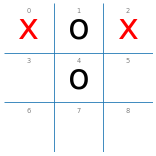


Win or draw:
Number of nodes searched: 64


[7,
 [['if',
   ['x', 'o', 'x', 'o', 'o', ' ', ' ', 'x', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'o', 'x', 'o', 'x', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'o', 'x', ' ', 'x', 'o'],
      'then',
      [6, 'draw']]]]],
  ['if',
   ['x', 'o', 'x', ' ', 'o', 'o', ' ', 'x', ' '],
   'then',
   [3,
    [['if',
      ['x', 'o', 'x', 'x', 'o', 'o', 'o', 'x', ' '],
      'then',
      [8, 'draw']],
     ['if',
      ['x', 'o', 'x', 'x', 'o', 'o', ' ', 'x', 'o'],
      'then',
      [6, 'win']]]]],
  ['if',
   ['x', 'o', 'x', ' ', 'o', ' ', 'o', 'x', ' '],
   'then',
   [3,
    [['if',
      ['x', 'o', 'x', 'x', 'o', 'o', 'o', 'x', ' '],
      'then',
      [8, 'draw']],
     ['if',
      ['x', 'o', 'x', 'x', 'o', ' ', 'o', 'x', 'o'],
      'then',
      [5, 'draw']]]]],
  ['if',
   ['x', 'o', 'x', ' ', 'o', ' ', ' ', 'x', 'o'],
   'then',
   [3,
    [['if', ['x', 'o', 'x', 'x', 'o', 'o', ' ', 'x', 'o'], 'then', [6, 'win']],
     ['if',
      ['x', '

CPU times: total: 0 ns
Wall time: 4.65 ms


In [43]:

board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
#board[3] = 'o'
board[4] = 'o'

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

In [44]:
print("Win only:")
%time display(and_or_search(board, player = 'x', draw_is_win = False))

Win only:
Number of nodes searched: 69


None

CPU times: total: 15.6 ms
Wall time: 4.23 ms


### Nhận xét kiểm thử 2 – X cần tìm đường hòa

Thực nghiệm được thực hiện trên trạng thái bàn cờ có X tại vị trí 0 và 2, O tại vị trí 1 và 4. Trong tình huống này, O đang đe dọa chiến thắng trên cột 1–4–7, vì vậy X cần đánh vào vị trí 7 để ngăn đối thủ thắng ngay.

Khi chạy AND-OR Search với `draw_is_win=True`, thuật toán lựa chọn nước đi 7 sau khi duyệt 64 nút. Kế hoạch điều kiện trả về cho phép X ứng phó với các nước đi tiếp theo của O nhằm bảo đảm kết quả thắng hoặc hòa.

Ngược lại, khi `draw_is_win=False`, thuật toán duyệt 69 nút và trả về `None`. Điều này cho thấy không tồn tại kế hoạch giúp X bảo đảm chiến thắng trước mọi phản ứng hợp lệ của đối thủ từ trạng thái đang xét.

Kết quả chứng minh sự khác biệt giữa mục tiêu bảo đảm không thua và mục tiêu bắt buộc phải thắng. AND-OR Search có thể tìm được kế hoạch phòng thủ để đạt kết quả hòa ngay cả khi không thể bảo đảm chiến thắng.

## a bad situation

Board:


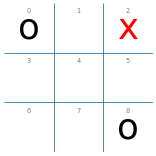


Win or draw:
Number of nodes searched: 155


None

CPU times: total: 15.6 ms
Wall time: 6.04 ms


In [45]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

In [46]:
print("Win only:")
%time display(and_or_search(board, player='x', draw_is_win=False))

Win only:
Number of nodes searched: 147


None

CPU times: total: 0 ns
Wall time: 5.06 ms


### Nhận xét kiểm thử 3 – Tình huống bất lợi

Trạng thái kiểm thử có O tại các vị trí 0 và 8, X tại vị trí 2. Đây là tình huống bất lợi được sử dụng để kiểm tra khả năng xây dựng kế hoạch điều kiện của AND-OR Search.

Khi chạy với `draw_is_win=True`, thuật toán duyệt 155 nút và trả về `None`, cho thấy không tìm được kế hoạch bảo đảm X đạt kết quả thắng hoặc hòa trước mọi phản ứng được xét của đối thủ.

Khi chạy với `draw_is_win=False`, thuật toán duyệt 147 nút và tiếp tục trả về `None`. Như vậy, thuật toán cũng không tìm được kế hoạch bảo đảm chiến thắng cho X.

Số nút tìm kiếm của hai chế độ khác nhau do điều kiện chấp nhận trạng thái kết thúc thay đổi, ảnh hưởng đến quá trình duyệt và loại bỏ các nhánh tìm kiếm.

Cần lưu ý rằng trạng thái kiểm thử có hai quân O và một quân X, không phù hợp với thứ tự lượt chơi thông thường nếu X là người đi trước. Do đó, kết quả được nhận xét theo trạng thái đầu vào và mô hình tìm kiếm của notebook, không dùng để khẳng định kết quả của một ván đấu hợp lệ.

## Empty board: Only a draw_is_win can be guaranteed

Board:


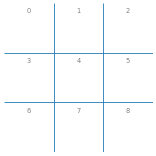


Win or draw:
Number of nodes searched: 966


[0,
 [['if',
   ['x', 'o', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
   'then',
   [2,
    [['if',
      ['x', 'o', 'x', 'o', ' ', ' ', ' ', ' ', ' '],
      'then',
      [4,
       [['if',
         ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '],
         'then',
         [6, 'win']],
        ['if',
         ['x', 'o', 'x', 'o', 'x', ' ', 'o', ' ', ' '],
         'then',
         [5,
          [['if',
            ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '],
            'then',
            [8, 'win']],
           ['if',
            ['x', 'o', 'x', 'o', 'x', 'x', 'o', ' ', 'o'],
            'then',
            [7, 'draw']]]]],
        ['if',
         ['x', 'o', 'x', 'o', 'x', ' ', ' ', 'o', ' '],
         'then',
         [5,
          [['if',
            ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '],
            'then',
            [8, 'win']],
           ['if',
            ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
            'then',
            [6, 'win']]]]],
        ['if',
        

CPU times: total: 46.9 ms
Wall time: 48.3 ms


In [47]:
board = empty_board() 

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

In [48]:
print("Win only:")
%time display(and_or_search(board, player = 'x', draw_is_win = False))

Win only:
Number of nodes searched: 16213


None

CPU times: total: 391 ms
Wall time: 412 ms


### Nhận xét kiểm thử 4 – Bàn cờ rỗng

Thực nghiệm được tiến hành từ trạng thái bàn cờ Tic-Tac-Toe rỗng, với cả 9 vị trí chưa được đánh.

Khi chạy AND-OR Search với `draw_is_win=True`, thuật toán duyệt 966 nút trong khoảng **48,3 ms** và lựa chọn vị trí 0 làm nước đi đầu tiên. Kết quả trả về là một kế hoạch điều kiện cho phép X ứng phó với các phản ứng khác nhau của đối thủ, bảo đảm đạt kết quả thắng hoặc hòa.

Khi thay đổi thành `draw_is_win=False`, thuật toán duyệt 16.213 nút trong khoảng **412 ms** nhưng trả về `None`. Điều này cho thấy X không thể xây dựng kế hoạch bảo đảm chiến thắng trước mọi phản ứng hợp lệ của O từ trạng thái ban đầu.

Số nút tìm kiếm ở chế độ chỉ chấp nhận thắng lớn hơn đáng kể do thuật toán không tìm được kế hoạch thỏa mãn mục tiêu và phải tiếp tục kiểm tra các nhánh khác. Trong khi đó, chế độ chấp nhận thắng hoặc hòa có thể dừng sớm khi tìm được kế hoạch phù hợp.

Kết quả minh họa khả năng xây dựng kế hoạch điều kiện của AND-OR Search, đồng thời cho thấy điều kiện mục tiêu có ảnh hưởng lớn đến số nút được duyệt và chi phí tìm kiếm.

## Experiments

### And-Or Tree Search vs. Random

Put AND-OR search into a wrapper agent function. Note that if AND-OR search cannot guarantee a win then
it does not return a plan, nut `None`. In this case, we do not know what the best (i.e., the least "bad") 
move is, so I make the agent play randomly. Other methods that we will learn about later can determine the utility of a move, even if it does not guarantee a win.

In [49]:
DEBUG = 0

def and_or_player(board, player = 'x'):
    plan = and_or_search(board, player)

    # if there is no plan then we do a random action
    if plan is None: 
        return np.random.choice(actions(board))
    else:
        return plan[0]


import numpy as np
import time

np.random.seed(1111)

start = time.perf_counter()

match_results = play(and_or_player, random_player, N=100)

elapsed = time.perf_counter() - start

print("=== AND-OR (X) VS RANDOM (O) ===")
print("Total games:", sum(match_results.values()))
print("X wins:", match_results['x'])
print("O wins:", match_results['o'])
print("Draws:", match_results['d'])
print(f"Total time: {elapsed:.3f} seconds")

=== AND-OR (X) VS RANDOM (O) ===
Total games: 100
X wins: 92
O wins: 0
Draws: 8
Total time: 2.990 seconds


In [50]:
# Random (X) vs AND-OR (O) - 100 games
np.random.seed(1111)

start = time.perf_counter()

results_reverse = play(random_player, and_or_player, N=100)

elapsed_reverse = time.perf_counter() - start

print("=== RANDOM (X) VS AND-OR (O) ===")
print("Total games:", sum(results_reverse.values()))
print("X wins:", results_reverse['x'])
print("O wins:", results_reverse['o'])
print("Draws:", results_reverse['d'])
print(f"Total time: {elapsed_reverse:.3f} seconds")

=== RANDOM (X) VS AND-OR (O) ===
Total games: 100
X wins: 0
O wins: 70
Draws: 30
Total time: 6.684 seconds


### Nhận xét thực nghiệm AND-OR Search vs Random

Thực nghiệm được tiến hành với 200 ván Tic-Tac-Toe, chia thành hai thiết lập: AND-OR đóng vai X (đi trước) đấu với Random đóng vai O và Random đóng vai X đấu với AND-OR đóng vai O. Mỗi thiết lập gồm 100 ván.

Ở thiết lập thứ nhất, AND-OR giành chiến thắng 92 ván (92%), hòa 8 ván (8%) và không thua ván nào. Tổng thời gian thực nghiệm là 2,990 giây.

Ở thiết lập thứ hai, khi AND-OR đóng vai O, tác tử thắng 70 ván (70%), hòa 30 ván (30%) và tiếp tục không thua ván nào. Tổng thời gian thực nghiệm là 6,684 giây.

Kết quả cho thấy AND-OR Search có khả năng lựa chọn nước đi hiệu quả khi đối đầu với tác tử Random. Tỷ lệ thắng khi đi trước cao hơn khi đi sau, trong khi cả hai thiết lập đều không ghi nhận thất bại.

Điểm nổi bật của AND-OR Search là xây dựng kế hoạch điều kiện dựa trên những phản ứng có thể xảy ra của đối thủ. Thay vì chỉ xác định một chuỗi nước đi cố định, thuật toán lựa chọn hành động phù hợp với từng trạng thái nhằm bảo đảm mục tiêu thắng hoặc hòa khi tìm được kế hoạch.

Tuy nhiên, kết quả thực nghiệm chỉ phản ánh hiệu quả của tác tử khi đối đầu với Random trong 100 ván cho mỗi thiết lập. Để đánh giá toàn diện hơn, cần so sánh thêm với các tác tử sử dụng chiến lược tìm kiếm khác như Minimax hoặc Alpha-Beta.

**Note how slow this is!**

My lazy implementation is a _simple reflex agent_ that recreates a conditional plan every time it is asked for an action. ut since And-Or search already produces a complete conditional plan for the empty board, a better implementation would use a _model-based reflex agent_ that store this precomputed plan and just follow it without more planing.

### And-Or Tree Search vs. And-Or Tree Search

In [51]:
# No randomness -> run only once

%time display(play(and_or_player, and_or_player, N = 1))

{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 250 ms
Wall time: 255 ms
